In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


In [6]:
df = pd.read_csv(r"C:\Users\shrey\OneDrive\Documents\Desktop\Student Performance Analysis\StudentPerformanceFactors.csv")
df.head()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [7]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (6607, 20)

Column Names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null

In [8]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [9]:
df.describe(include="object")

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


In [10]:
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values.sort_values(by="Percentage", ascending=False)

,Missing Values,Percentage
Parental_Education_Level,90,1.362192
Teacher_Quality,78,1.180566
Distance_from_Home,67,1.014076
Hours_Studied,0,0.000000
Access_to_Resources,0,0.000000
Parental_Involvement,0,0.000000
Attendance,0,0.000000
Extracurricular_Activities,0,0.000000
Motivation_Level,0,0.000000
Internet_Access,0,0.000000


In [11]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [12]:
df = df.drop_duplicates()

numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include="object").columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Values After Cleaning:")
print(df.isnull().sum().sum())

print("Dataset Shape After Cleaning:", df.shape)

Missing Values After Cleaning:
0
Dataset Shape After Cleaning: (6607, 20)


In [13]:
df.dtypes

Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Education_Level      object
Distance_from_Home            object
Gender                        object
Exam_Score                     int64
dtype: object

In [14]:
df["Performance_Level"] = pd.cut(
    df["Exam_Score"],
    bins=[-np.inf, 60, 75, 90, np.inf],
    labels=["Needs Improvement", "Average", "Good", "Excellent"]
)

df[["Exam_Score", "Performance_Level"]].head(10)

,Exam_Score,Performance_Level
0,67,Average
1,61,Average
2,74,Average
3,71,Average
4,70,Average
5,71,Average
6,67,Average
7,66,Average
8,69,Average
9,72,Average


In [15]:
print("Average Exam Score:", round(df["Exam_Score"].mean(), 2))
print("Highest Exam Score:", df["Exam_Score"].max())
print("Lowest Exam Score:", df["Exam_Score"].min())
print("Median Exam Score:", df["Exam_Score"].median())
print("Standard Deviation:", round(df["Exam_Score"].std(), 2))

Average Exam Score: 67.24
Highest Exam Score: 101
Lowest Exam Score: 55
Median Exam Score: 67.0
Standard Deviation: 3.89


Performance_Level
Average              6386
Needs Improvement     145
Good                   54
Excellent              22
Name: count, dtype: int64


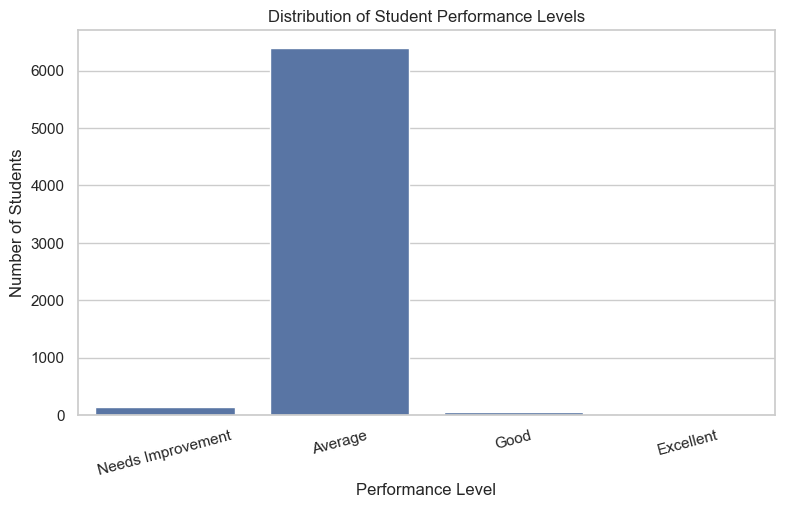

In [16]:
performance_count = df["Performance_Level"].value_counts()

print(performance_count)

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="Performance_Level", order=["Needs Improvement", "Average", "Good", "Excellent"])
plt.title("Distribution of Student Performance Levels")
plt.xlabel("Performance Level")
plt.ylabel("Number of Students")
plt.xticks(rotation=15)
plt.show()

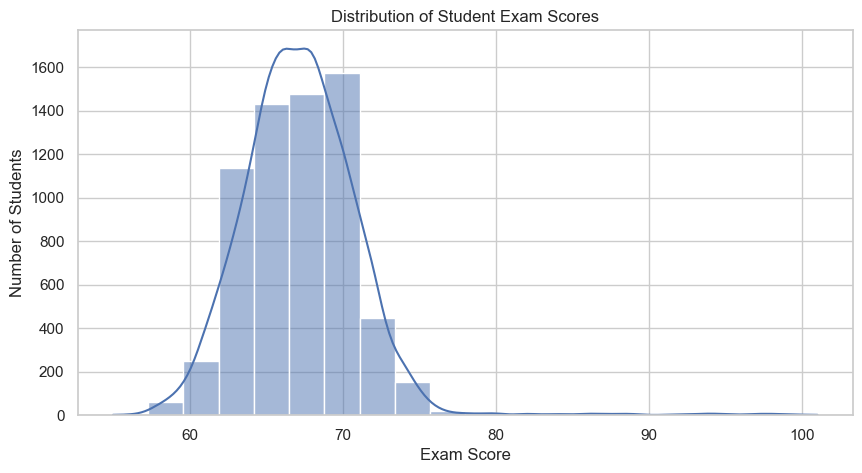

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Exam_Score"], bins=20, kde=True)
plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.show()

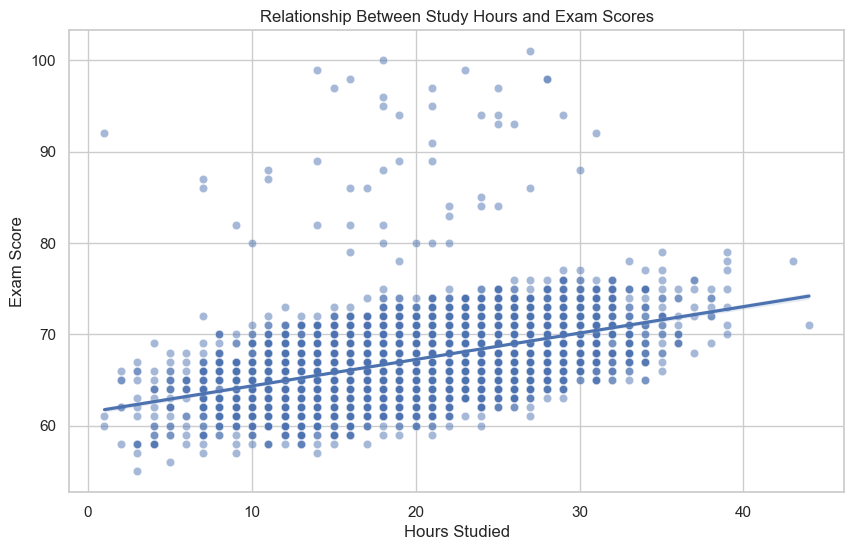

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score", alpha=0.5)
sns.regplot(data=df, x="Hours_Studied", y="Exam_Score", scatter=False)
plt.title("Relationship Between Study Hours and Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.show()

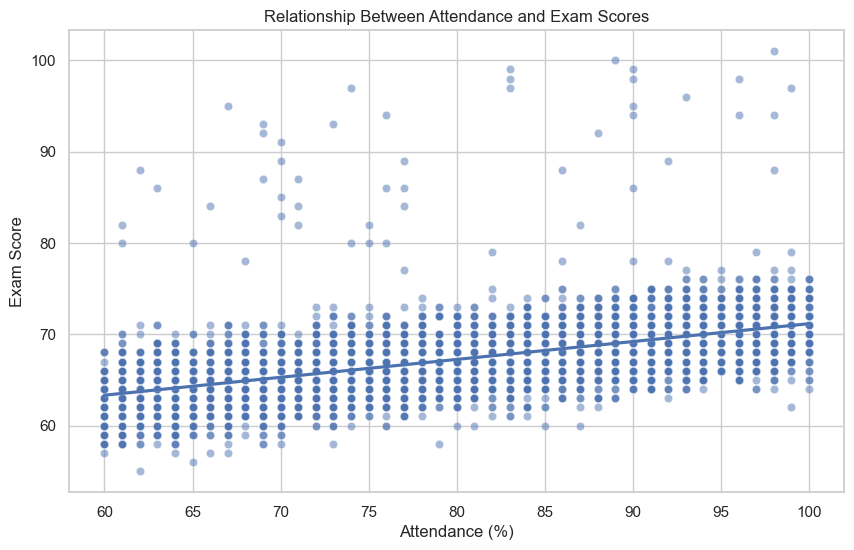

In [19]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Attendance", y="Exam_Score", alpha=0.5)
sns.regplot(data=df, x="Attendance", y="Exam_Score", scatter=False)
plt.title("Relationship Between Attendance and Exam Scores")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.show()

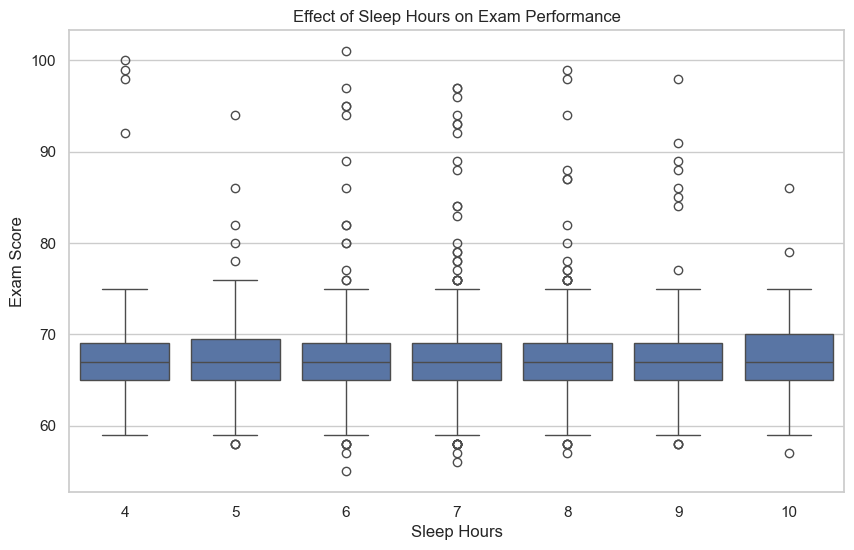

In [20]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Sleep_Hours", y="Exam_Score")
plt.title("Effect of Sleep Hours on Exam Performance")
plt.xlabel("Sleep Hours")
plt.ylabel("Exam Score")
plt.show()

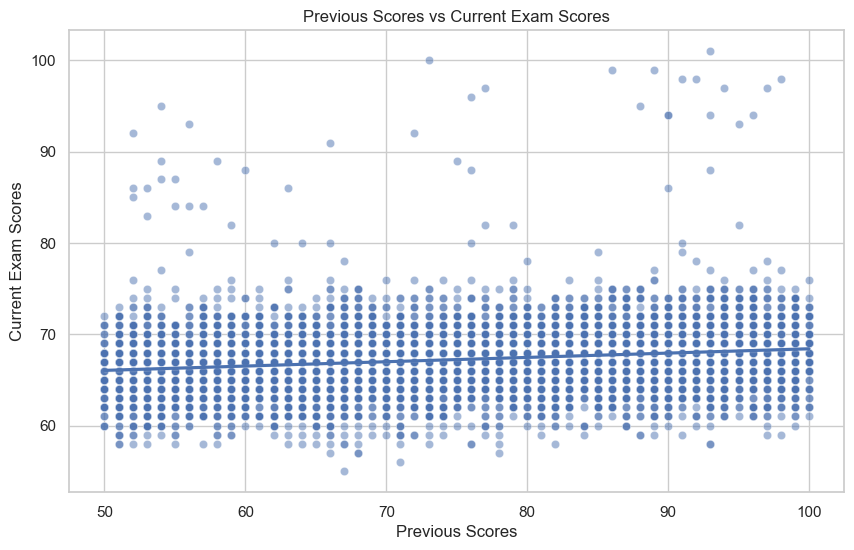

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Previous_Scores", y="Exam_Score", alpha=0.5)
sns.regplot(data=df, x="Previous_Scores", y="Exam_Score", scatter=False)
plt.title("Previous Scores vs Current Exam Scores")
plt.xlabel("Previous Scores")
plt.ylabel("Current Exam Scores")
plt.show()

Parental_Involvement
High      68.092767
Medium    67.098156
Low       66.358265
Name: Exam_Score, dtype: float64


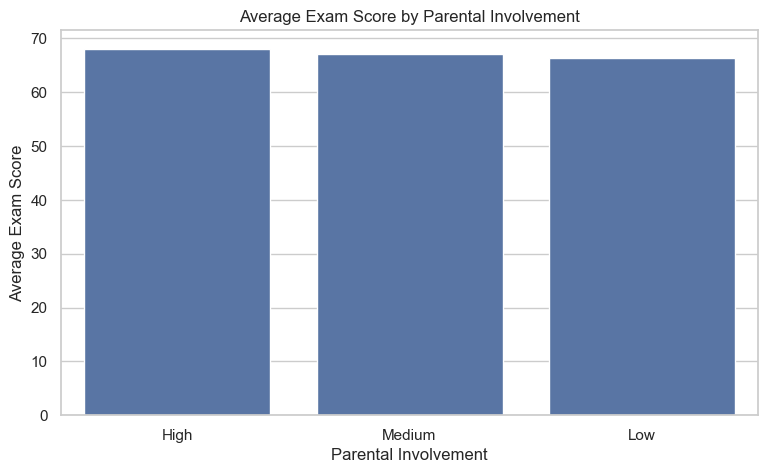

In [22]:
parental_analysis = df.groupby("Parental_Involvement", observed=False)["Exam_Score"].mean().sort_values(ascending=False)

print(parental_analysis)

plt.figure(figsize=(9, 5))
sns.barplot(x=parental_analysis.index, y=parental_analysis.values)
plt.title("Average Exam Score by Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Average Exam Score")
plt.show()

Motivation_Level
High      67.704321
Medium    67.330648
Low       66.752194
Name: Exam_Score, dtype: float64


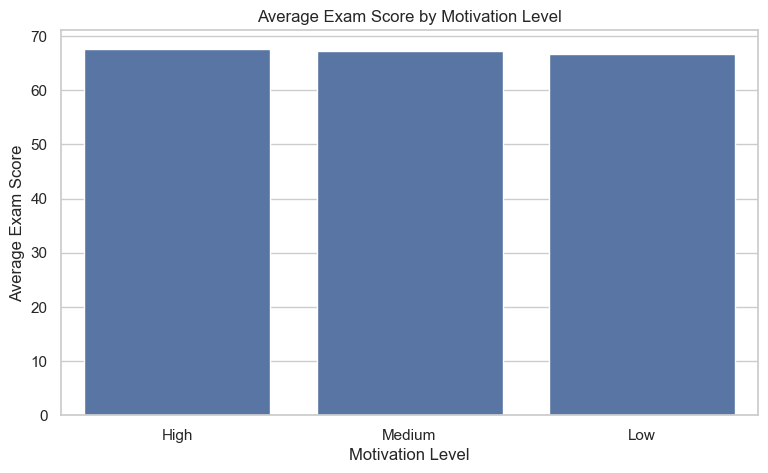

In [23]:
motivation_analysis = df.groupby("Motivation_Level", observed=False)["Exam_Score"].mean().sort_values(ascending=False)

print(motivation_analysis)

plt.figure(figsize=(9, 5))
sns.barplot(x=motivation_analysis.index, y=motivation_analysis.values)
plt.title("Average Exam Score by Motivation Level")
plt.xlabel("Motivation Level")
plt.ylabel("Average Exam Score")
plt.show()

Tutoring_Sessions
0    66.489755
1    66.980266
2    67.567010
3    67.894737
4    68.229236
5    69.067961
6    71.666667
7    69.857143
8    69.000000
Name: Exam_Score, dtype: float64


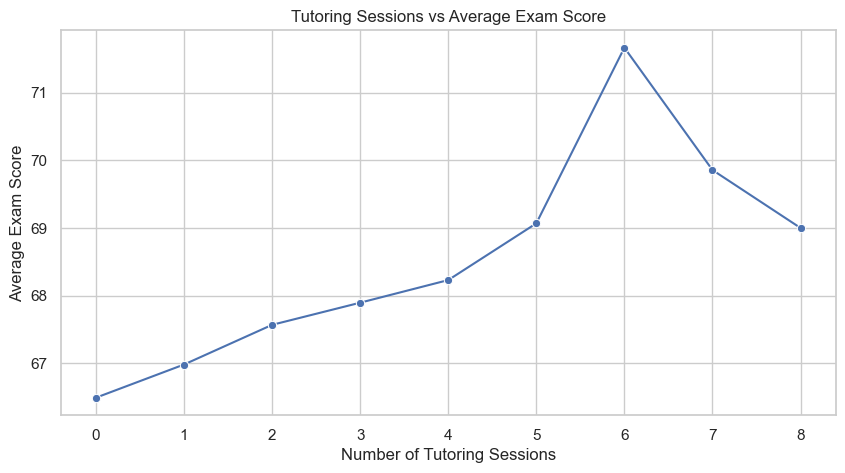

In [24]:
tutoring_analysis = df.groupby("Tutoring_Sessions")["Exam_Score"].mean()

print(tutoring_analysis)

plt.figure(figsize=(10, 5))
sns.lineplot(x=tutoring_analysis.index, y=tutoring_analysis.values, marker="o")
plt.title("Tutoring Sessions vs Average Exam Score")
plt.xlabel("Number of Tutoring Sessions")
plt.ylabel("Average Exam Score")
plt.show()

Internet_Access
No     66.535070
Yes    67.292895
Name: Exam_Score, dtype: float64


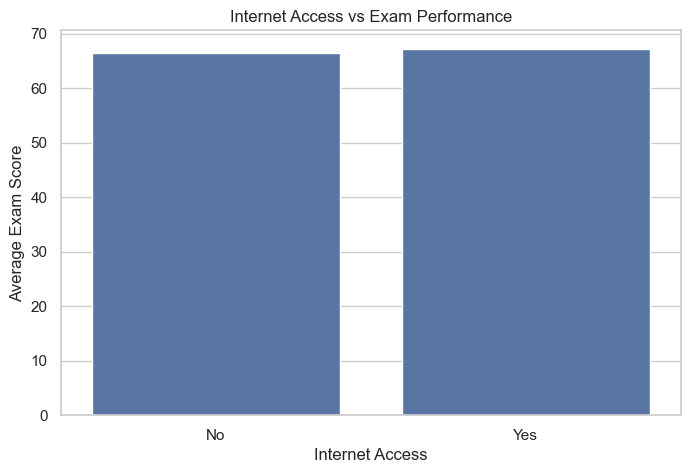

In [25]:
internet_analysis = df.groupby("Internet_Access", observed=False)["Exam_Score"].mean()

print(internet_analysis)

plt.figure(figsize=(8, 5))
sns.barplot(x=internet_analysis.index, y=internet_analysis.values)
plt.title("Internet Access vs Exam Performance")
plt.xlabel("Internet Access")
plt.ylabel("Average Exam Score")
plt.show()

School_Type
Private    67.287705
Public     67.212919
Name: Exam_Score, dtype: float64


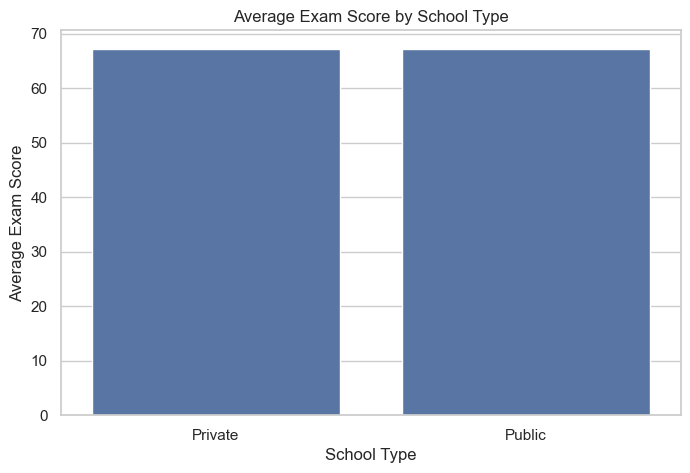

In [26]:
school_analysis = df.groupby("School_Type", observed=False)["Exam_Score"].mean()

print(school_analysis)

plt.figure(figsize=(8, 5))
sns.barplot(x=school_analysis.index, y=school_analysis.values)
plt.title("Average Exam Score by School Type")
plt.xlabel("School Type")
plt.ylabel("Average Exam Score")
plt.show()

In [27]:
gender_analysis = df.groupby("Gender", observed=False)["Exam_Score"].agg(["mean", "median", "count"])

gender_analysis

,mean,median,count
Gender,,,
Female,67.244898,67.0,2793
Male,67.228894,67.0,3814


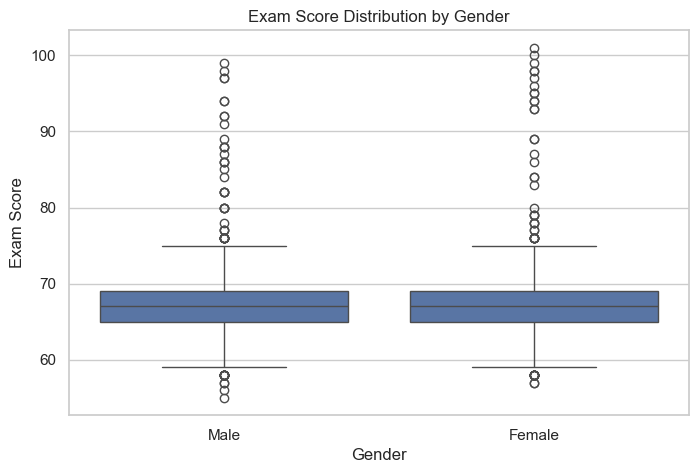

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Gender", y="Exam_Score")
plt.title("Exam Score Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Exam Score")
plt.show()

In [29]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
Hours_Studied,1.000000,-0.009908,0.010977,0.024846,-0.014282,0.004624,0.445455
Attendance,-0.009908,1.000000,-0.015918,-0.020186,0.014324,-0.022435,0.581072
Sleep_Hours,0.010977,-0.015918,1.000000,-0.021750,-0.012216,-0.000378,-0.017022
Previous_Scores,0.024846,-0.020186,-0.021750,1.000000,-0.013122,-0.011274,0.175079
Tutoring_Sessions,-0.014282,0.014324,-0.012216,-0.013122,1.000000,0.017733,0.156525
Physical_Activity,0.004624,-0.022435,-0.000378,-0.011274,0.017733,1.000000,0.027824
Exam_Score,0.445455,0.581072,-0.017022,0.175079,0.156525,0.027824,1.000000


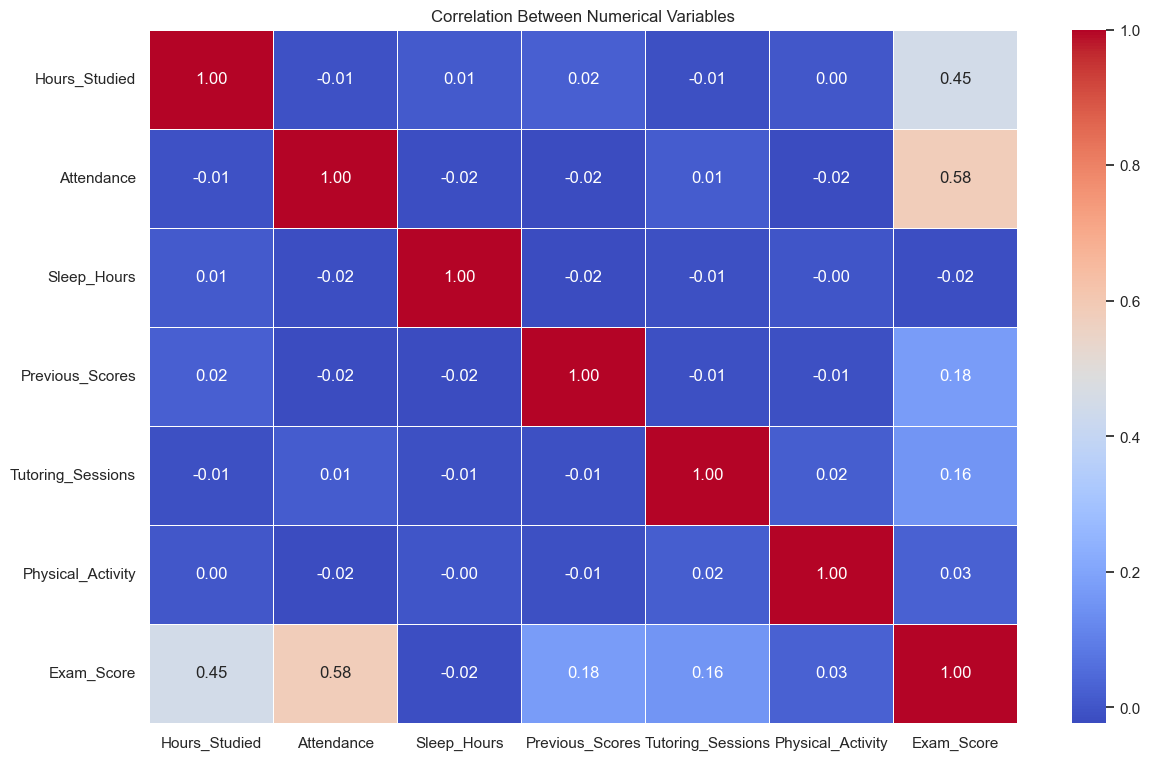

In [30]:
plt.figure(figsize=(14, 9))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Between Numerical Variables")
plt.show()